In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5))]
)

# Load Dataset

In [4]:
from torchvision.datasets import MNIST

# Create Dataset

In [ ]:
trainset = MNIST(root='./Data2', train=True, transform=transform)
testset = MNIST(root='./Data2', train=False, transform=transform)

# Create Dataloader

In [5]:
train_dataloader = DataLoader(trainset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(testset, batch_size=64)

# Build CNN Model

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv_layer = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )
        self.fc_layer = nn.Sequential(
            nn.Linear(7*7*64, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x =  self.conv_layer(x)
        x = x.view(x.size(0), -1)
        x = self.fc_layer(x)

        return x

In [7]:
model = CNN()
crie = nn.CrossEntropyLoss()
optimz = optim.Adam(model.parameters())

# Train CNN Model

In [8]:
epochs = 10
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for xb, yb in train_dataloader:
        optimz.zero_grad()
        
        output = model(xb)
        
        loss = crie(output, yb)
        
        loss.backward()
        
        optimz.step()

        total_loss += loss.item()
        
    print(f"epoch = {epoch+1}/{epochs} & loss={total_loss/len(train_dataloader)}")    

epoch = 1/10 & loss=0.15863677322232067
epoch = 2/10 & loss=0.04616790357356601
epoch = 3/10 & loss=0.031443802452528785
epoch = 4/10 & loss=0.024285975349585473
epoch = 5/10 & loss=0.018757912735587846
epoch = 6/10 & loss=0.013042097270748843
epoch = 7/10 & loss=0.012865141401096729
epoch = 8/10 & loss=0.008261416847204767
epoch = 9/10 & loss=0.009305967071631817
epoch = 10/10 & loss=0.006244032709428948


# Testing Accuracy

In [9]:
correct = 0
total = 0

all_preds = []
all_labels = [] 

model.eval()
with torch.no_grad():
    for xb, yb in test_dataloader:
        output = model(xb)
        _, predicted = torch.max(output, 1)

        correct += (predicted == yb).sum().item()
        total += yb.size(0)

        all_preds.extend(predicted.numpy())
        all_labels.extend(yb.numpy())

print(f"accuracy = {(correct/total) * 100}")    

accuracy = 99.16


# Training Accuracy

In [10]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for xb, yb in train_dataloader:
        output = model(xb)

        _, predicted = torch.max(output, 1)

        total += yb.size(0)
        correct += (predicted == yb).sum().item()

train_accuracy = 100 * correct / total

print(f"Training Accuracy: {train_accuracy:.2f}%")

Training Accuracy: 99.84%


# Visualize result

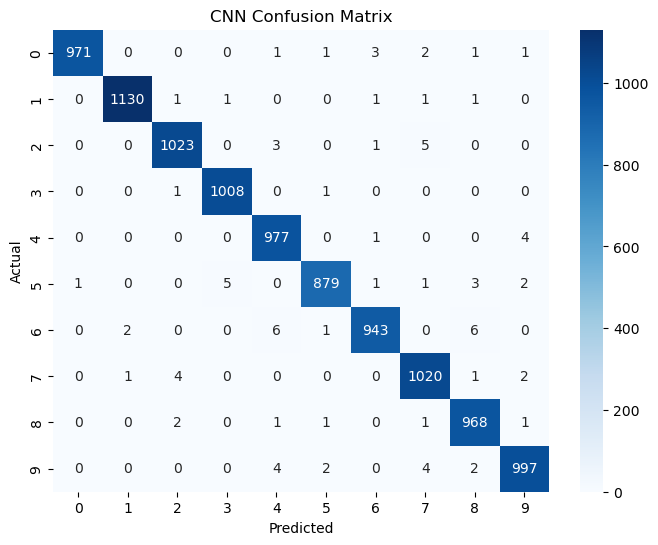

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")

plt.show()

# RNN

In [12]:
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=1):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        #RNN 
        self.rnn = nn.RNN(input_size=input_size,
                            hidden_size=hidden_size,
                            num_layers=num_layers,
                            batch_first=True)

        #fc
        self.fc = nn.Linear(hidden_size, 10) #i/p, o/p

    def forward(self, x):
        # optional step => shape(numof layers, batch_size, hidden_size)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)

        out, _ = self.rnn(x, h0)
        #1st val = hidden state of all the timesteps => batch, seq_len, hidden size
        # 2nd val = final hidden state of last timestep

        out = self.fc(out[:, -1, :]) #we need the last timestep
        return out

In [14]:
input_size = 28

model = RNN(input_size)

crie = nn.CrossEntropyLoss()
optimz= optim.Adam(model.parameters())

In [15]:
epochs = 10

for epoch in range(epochs):

    model.train()
    total_loss = 0.0

    for xb, yb in train_dataloader:

        # [batch, 1, 28, 28]
        #        ↓
        # [batch, 28, 28]

        xb = xb.squeeze(1)

        optimz.zero_grad()

        outputs = model(xb)

        loss = crie(outputs, yb)

        loss.backward()

        optimz.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_dataloader)

    print(
        f"Epoch = {epoch+1}/{epochs}, "
        f"Loss = {avg_loss:.4f}"
    )

Epoch = 1/10, Loss = 0.7417
Epoch = 2/10, Loss = 0.3573
Epoch = 3/10, Loss = 0.2526
Epoch = 4/10, Loss = 0.2022
Epoch = 5/10, Loss = 0.1784
Epoch = 6/10, Loss = 0.1601
Epoch = 7/10, Loss = 0.1490
Epoch = 8/10, Loss = 0.1486
Epoch = 9/10, Loss = 0.1285
Epoch = 10/10, Loss = 0.1265


In [18]:
model.eval()

total_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for xb, yb in test_dataloader:

        xb = xb.squeeze(1)

        outputs = model(xb)

        loss = crie(outputs, yb)

        total_loss += loss.item()

        predicted = outputs.argmax(dim=1)

        total += yb.size(0)
        correct += (predicted == yb).sum().item()

avg_loss = total_loss / len(test_dataloader)
accuracy = 100 * correct / total

print(f"Test Loss: {avg_loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}%")

Test Loss: 0.1570
Test Accuracy: 95.62%
